# Tour do pipeline

> **Projeto conceitual de candidatura · dados simulados.** Não é material oficial da ADR Empreendimentos.

Este notebook percorre o `pipeline.py` passo a passo: lê os 6 arquivos brutos, aplica as regras de
tratamento R1 a R7 mostrando o antes e o depois de cada uma, valida o resultado e termina na quarentena
e no relatório de qualidade.

Ele não reimplementa nada: chama as mesmas funções de `etl/` que o pipeline chama, sobre os brutos que
estão no repositório (`dados/brutos/`).

| Passo | O que faz | Onde está |
|---|---|---|
| 1. Ler | cada arquivo vira uma tabela com os nomes do banco; nenhum valor é corrigido | `etl/ler.py` |
| 2. Tratar | as regras R1 a R7 limpam o que dá para limpar e mandam o resto para a quarentena | `etl/tratar/` |
| 3. Validar | 10 checagens; se uma falhar, o pipeline para sem gravar nada | `etl/validar.py` |
| 4. Carregar | grava os CSVs limpos e monta o banco PostgreSQL do painel | `etl/carregar.py` |

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

# o notebook roda de notebooks/ (Jupyter, nbconvert) ou da raiz do repositório
RAIZ = Path.cwd() if (Path.cwd() / "etl").is_dir() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from etl import config, ler, validar
from etl.tratar import REGRAS, tratar
from etl.tratar import r1_duplicatas, r3_canais, r5_valores
from etl.tratar.comum import Resultado, propagar_quarentena
from pipeline import TABELAS_DO_ARQUIVO

# as cores do painel (web/src/tema/paleta.ts): um destaque em cobre, o resto em cinza
COBRE, CINZA = "#cc8040", "#666666"
FUNDO, TEXTO, TEXTO_2, BORDA = "#171717", "#f2f2f2", "#a6a6a6", "#333333"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": BORDA, "axes.labelcolor": TEXTO_2, "text.color": TEXTO,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
    "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.max_colwidth", 90)


def milhar(n):
    """1234 vira 1.234."""
    return f"{n:,}".replace(",", ".")

## 1. O ponto de partida

Três sistemas que não conversam entre si entregam 6 arquivos, cada um com o seu formato: o CRM exporta
CSV em UTF-8, a planilha do comercial é `.xlsx` e o ERP exporta CSV em Latin-1. O `ler.ler` só entende
formatos (codificação, separador, nome de coluna); os valores chegam do jeito que estão.

In [2]:
lidos = ler.ler(config.DIR_BRUTOS)

SISTEMA = {"crm_leads.csv": "CRM", "comercial_espelho.xlsx": "Planilha do comercial",
           "comercial_parceiros.xlsx": "Planilha do comercial", "erp_parcelas.csv": "ERP financeiro",
           "erp_baixas.csv": "ERP financeiro", "diretoria_metas.xlsx": "Diretoria"}
pd.DataFrame([{"arquivo": arquivo, "sistema": SISTEMA[arquivo], "vira as tabelas": ", ".join(tabelas),
               "linhas": milhar(sum(len(lidos[t]) for t in tabelas))}
              for arquivo, tabelas in TABELAS_DO_ARQUIVO.items()])

,arquivo,sistema,vira as tabelas,linhas
0,crm_leads.csv,CRM,lead,16.479
1,comercial_espelho.xlsx,Planilha do comercial,"empreendimento, unidade, venda",681
2,comercial_parceiros.xlsx,Planilha do comercial,"imobiliaria, corretor",44
3,erp_parcelas.csv,ERP financeiro,parcela,10.122
4,erp_baixas.csv,ERP financeiro,pagamento,5.594
5,diretoria_metas.xlsx,Diretoria,meta_mensal,105


O CRM é o arquivo mais sujo: o telefone vem em vários formatos, o canal de origem é digitado à mão e o
mesmo cliente às vezes entra duas vezes. Uma amostra:

In [3]:
lead_bruto = lidos["lead"]
canal_fora_do_rotulo = ~lead_bruto["canal"].isin(list(r3_canais.ROTULOS))
lead_bruto.loc[canal_fora_do_rotulo, ["id", "nome", "telefone", "email", "canal", "data_entrada"]].sample(8, random_state=3)

,id,nome,telefone,email,canal,data_entrada
9106,9107,Benício Vargas,083 98848 9822,beniciovargas@gmail.com,site,23/04/2025 21:12
7335,7336,Hellena Oliveira,(83) 96828-4106,NaN,Indicação de cliente,30/11/2024 20:17
4101,4102,Julia Sá,083 90587 4696,julia_sa@uol.com.br,imobiliaria,25/04/2024 16:22
13895,13896,Lorenzo Sá,(83) 96682-2059,lorenzosa11@gmail.com,indicacao,10/04/2026 15:40
8944,8945,Lucas Gabriel da Rocha,+5583988443355,lucas_gabriel_da_rocha@gmail.com,imobiliaria,02/04/2025 11:54
14431,14432,Thiago Farias,(83) 97339-9495,thiago_farias30@gmail.com,Site ADR,30/05/2026 09:07
8036,8037,Maria Fernanda Costela,084 92556 8563,mariafernandacostela@outlook.com,insta,12/01/2025 09:26
11701,11702,Isis Gomes,+5583907878471,isis.gomes@hotmail.com,Site ADR,01/11/2025 10:48


## 2. Tratar

O `tratar()` aplica as regras numa ordem fixa (`etl/tratar/__init__.py`): primeiro as conversões de
texto em data e em dinheiro, depois R1, R6, R2, R3, as datas impossíveis do R4, os outliers do R5, o R7
e, no fim, a cascata da quarentena. Cada passo recebe as tabelas do anterior e devolve as tabelas
tratadas, os **registros** (que viram o relatório de qualidade) e as linhas que mandou para a
**quarentena**, com o motivo.

Para mostrar o antes e o depois, a célula abaixo percorre a mesma lista `REGRAS` guardando as tabelas
depois de cada passo, e confere no fim que o resultado é idêntico ao do `tratar()` do pipeline.

In [4]:
fotos = {"lido": lidos}  # as tabelas depois de cada passo
passos = {}
acumulado = Resultado(dict(lidos))
for regra in REGRAS:
    nome = f"{regra.__module__.split('.')[-1]}.{regra.__name__}"
    passo = regra(acumulado.tabelas)
    fotos[nome], passos[nome] = passo.tabelas, passo
    acumulado = Resultado(passo.tabelas, acumulado.registros + passo.registros, acumulado.quarentena + passo.quarentena)
passos["cascata"] = propagar_quarentena(acumulado.tabelas, acumulado.quarentena)
final = Resultado(passos["cascata"].tabelas, acumulado.registros + passos["cascata"].registros,
                  acumulado.quarentena + passos["cascata"].quarentena)

oficial = tratar(lidos)
assert all(final.tabelas[t].equals(oficial.tabelas[t]) for t in oficial.tabelas)
assert final.quarentena == oficial.quarentena
print("Passos:", " → ".join(passos))


def registros(nome):
    """O que um passo registrou, como aparece no relatório de qualidade."""
    return pd.DataFrame([{"regra": r.regra, "origem": r.origem, "o que fez": r.descricao,
                          "linhas": r.linhas_afetadas, "ação": r.acao} for r in passos[nome].registros])


def antes_e_depois(tabela, colunas, ids, antes, depois):
    """As mesmas linhas (pelo id) em duas fotos, coluna ao lado de coluna."""
    a = fotos[antes][tabela].set_index("id").loc[ids, colunas]
    d = fotos[depois][tabela].set_index("id").reindex(ids)[colunas]
    lado = pd.concat({"antes": a, "depois": d}, axis=1).swaplevel(axis=1)
    return lado[[(c, quando) for c in colunas for quando in ("antes", "depois")]]

Passos: r4_datas.converter → r5_valores.converter → r1_duplicatas.tratar → r6_vazios.tratar → r2_textos.tratar → r3_canais.tratar → r4_datas.barrar_impossiveis → r5_valores.corrigir_outliers → r7_orfaos.tratar → cascata


### Conversões · R4 (datas) e R5 (dinheiro)

O CSV chega todo em texto. O R4 lê as datas no formato de cada sistema; um lote do CRM importado de
outra ferramenta veio como `aaaa-mm-dd hh:mm:ss`, e ele é contado como sujeira. O R5 converte
`R$ 1.234,56` em número.

In [5]:
# 2 leads no formato do CRM e 2 do lote importado: depois da conversão, todos viram data
alternativas = passos["r4_datas.converter"].registros[0].ids[:2]
antes_e_depois("lead", ["data_entrada"], [1, 2] + alternativas, "lido", "r4_datas.converter")

data_entrada                    
                  antes              depois
id                                         
1      01/01/2023 08:11 2023-01-01 08:11:00
2      01/01/2023 08:15 2023-01-01 08:15:00
4   2023-01-01 08:23:00 2023-01-01 08:23:00
32  2023-01-01 12:51:00 2023-01-01 12:51:00

In [6]:
antes_e_depois("parcela", ["vencimento", "valor"], [1, 2, 3], "lido", "r5_valores.converter")

vencimento                    valor          
         antes     depois         antes    depois
id                                               
1   2023-02-01 2023-02-01  R$ 19.820,22  19820.22
2   2023-03-01 2023-03-01  R$ 19.820,23  19820.23
3   2023-04-01 2023-04-01   R$ 2.831,46   2831.46

In [7]:
pd.concat([registros("r4_datas.converter"), registros("r5_valores.converter")], ignore_index=True)

,regra,origem,o que fez,linhas,ação
0,R4,crm_leads.csv,Data de entrada no formato aaaa-mm-dd hh:mm:ss,792,corrigido
1,R5,erp_parcelas.csv,"Valor em texto (R$ 1.234,56) convertido para número",10122,convertido
2,R5,erp_baixas.csv,"Valor em texto (R$ 1.234,56) convertido para número",5594,convertido


### R1 · Leads duplicados

A mesma pessoa entra duas vezes no CRM (pelo site e pelo WhatsApp, por exemplo), com o telefone escrito
de outro jeito. O R1 padroniza o telefone para o formato internacional (`+5583…`) e junta num grupo os
leads com o mesmo telefone ou o mesmo e-mail. Fica o lead mais antigo, com o andamento da linha mais
avançada no funil.

In [8]:
antes_r1 = fotos["r5_valores.converter"]["lead"].reset_index(drop=True)
grupo = pd.Series(r1_duplicatas._grupos(r1_duplicatas.telefone_e164(antes_r1["telefone"]),
                                        r1_duplicatas._email_para_casar(antes_r1["email"])))
telefone = r1_duplicatas.telefone_e164(antes_r1["telefone"])
pares = antes_r1.assign(grupo=grupo, telefone_padrao=telefone)[grupo.duplicated(keep=False)]
# um par reconhecido pelo telefone, escrito de dois jeitos diferentes
mesmo_telefone = pares.groupby("grupo").filter(lambda p: p["telefone_padrao"].nunique() == 1 and p["telefone"].nunique() == 2)
exemplo = mesmo_telefone["grupo"].iloc[0]
COLUNAS = ["id", "nome", "telefone", "email", "canal", "data_entrada", "etapa"]
antes_r1.loc[grupo == exemplo, COLUNAS]

,id,nome,telefone,email,canal,data_entrada,etapa
2,3,Ana Júlia Nascimento,83941047729,anajulianascimento@gmail.com,TikTok,2023-01-01 08:19:00,perdido
15845,15846,Ana Júlia Nascimento,083 94104 7729,NaN,TikTok,2023-01-24 09:49:00,perdido


Depois do R1, o grupo vira uma linha só, com o telefone padronizado:

In [9]:
ids_do_grupo = antes_r1.loc[grupo == exemplo, "id"]
fotos["r1_duplicatas.tratar"]["lead"].query("id in @ids_do_grupo")[COLUNAS]

,id,nome,telefone,email,canal,data_entrada,etapa
2,3,Ana Júlia Nascimento,+5583941047729,anajulianascimento@gmail.com,TikTok,2023-01-01 08:19:00,perdido


634 pessoas entraram duas vezes; nenhuma entrou três vezes ou mais.


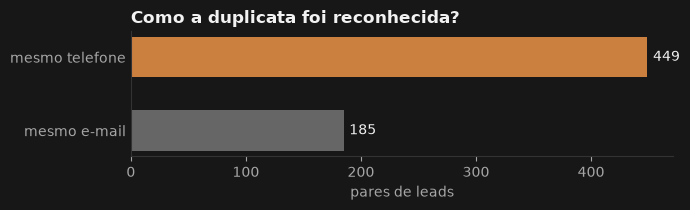

,regra,origem,o que fez,linhas,ação
0,R1,crm_leads.csv,Leads duplicados (mesmo telefone ou e-mail) mesclados no mais antigo,634,mesclado


In [10]:
print(f"{milhar(pares['grupo'].nunique())} pessoas entraram duas vezes; nenhuma entrou três vezes ou mais.")
como = pares.groupby("grupo")["telefone_padrao"].nunique().map({1: "mesmo telefone", 2: "mesmo e-mail"})
como = como.value_counts().reindex(["mesmo telefone", "mesmo e-mail"])

fig, ax = plt.subplots(figsize=(7, 2.2))
barras = ax.barh(como.index[::-1], como.values[::-1], color=[CINZA, COBRE], height=0.55)
ax.bar_label(barras, labels=[milhar(v) for v in como.values[::-1]], padding=4, color=TEXTO)
ax.set_title("Como a duplicata foi reconhecida?")
ax.set_xlabel("pares de leads")
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()
registros("r1_duplicatas.tratar")

### R6 · Vazios

Venda sem corretor na planilha do comercial é venda direta. E-mail sem a forma `algo@dominio.ext` vira
nulo: e-mail errado é pior que nenhum.

In [11]:
invalidos = passos["r6_vazios.tratar"].registros[1].ids[:4]
antes_e_depois("lead", ["email"], invalidos, "r1_duplicatas.tratar", "r6_vazios.tratar")

email       
                                     antes depois
id                                               
73             ana_carolina_camara22@yahoo    NaN
125               carolina_sales75@hotmail    NaN
143             bento_costa20@@hotmail.com    NaN
173  ana_carolina_casa_grande@@outlook.com    NaN

In [12]:
registros("r6_vazios.tratar")

,regra,origem,o que fez,linhas,ação
0,R6,comercial_espelho.xlsx,Venda sem corretor preenchida com Venda direta,20,corrigido
1,R6,crm_leads.csv,E-mail inválido apagado,285,nulo


### R2 · Textos

O bairro do empreendimento e o nome do corretor chegam escritos de vários jeitos. O bairro passa por um
de-para; o nome do corretor casa com o cadastro em 3 tentativas (igual depois de padronizar, inicial +
sobrenome e parecido o bastante). O nome que não casa, ou que casa com mais de um corretor, leva a linha
para a quarentena.

In [13]:
antes_e_depois("empreendimento", ["nome", "bairro"], passos["r2_textos.tratar"].registros[0].ids,
               "r6_vazios.tratar", "r2_textos.tratar")

nome                           bairro                
                antes             depois         antes          depois
id                                                                    
1   Mares Cabo Branco  Mares Cabo Branco     C. Branco     Cabo Branco
3       Mares Seaview      Mares Seaview   Jd. Oceania  Jardim Oceania
5         Mares Sense        Mares Sense  CABO BRANCO      Cabo Branco

In [14]:
cadastro = lidos["corretor"].set_index("id")["nome"]
casados = fotos["r6_vazios.tratar"]["lead"].merge(fotos["r2_textos.tratar"]["lead"][["id", "corretor_id"]], on="id")
casados["nome no cadastro"] = casados["corretor_id"].map(cadastro)
casados.loc[casados["corretor_nome"] != casados["nome no cadastro"], ["id", "corretor_nome", "corretor_id", "nome no cadastro"]].dropna().drop_duplicates("corretor_nome").head(6)

,id,corretor_nome,corretor_id,nome no cadastro
130,131,E. Dias,7,Elisa Dias
169,170,K. Nogueira,9,Kevin Nogueira
248,249,KAIQUE MENDES,5,Kaique Mendes
282,283,K. Mendes,5,Kaique Mendes
428,429,ELISA DIAS,7,Elisa Dias
446,447,Sara Fogaça,8,Sara Fogaça


In [15]:
pd.DataFrame([{"tabela": q["tabela"], "id": q["registro"]["id"], "motivo": q["motivo"]}
              for q in passos["r2_textos.tratar"].quarentena])

,tabela,id,motivo
0,lead,6914,"nome de corretor ambíguo: J. Silva → João Silva, José Silva"
1,lead,8365,"nome de corretor ambíguo: J. Silva → João Silva, José Silva"
2,lead,13552,"nome de corretor ambíguo: J. Silva → João Silva, José Silva"


In [16]:
registros("r2_textos.tratar")

,regra,origem,o que fez,linhas,ação
0,R2,comercial_espelho.xlsx,Bairro padronizado pelo de-para,3,corrigido
1,R2,crm_leads.csv,Nome de corretor (lead) casado com o cadastro,235,corrigido
2,R2,crm_leads.csv,Nome de corretor (lead) ambíguo ou fora do cadastro,3,quarentena
3,R2,comercial_espelho.xlsx,Nome de corretor (venda) casado com o cadastro,8,corrigido


### R3 · Canais

O canal de origem do lead é digitado à mão no CRM. Um de-para de sinônimos leva cada texto a um dos
canais oficiais; o que ele não conhece vira `outro`, e a lista desses textos vai para o relatório, para
o analista acrescentar ao dicionário.

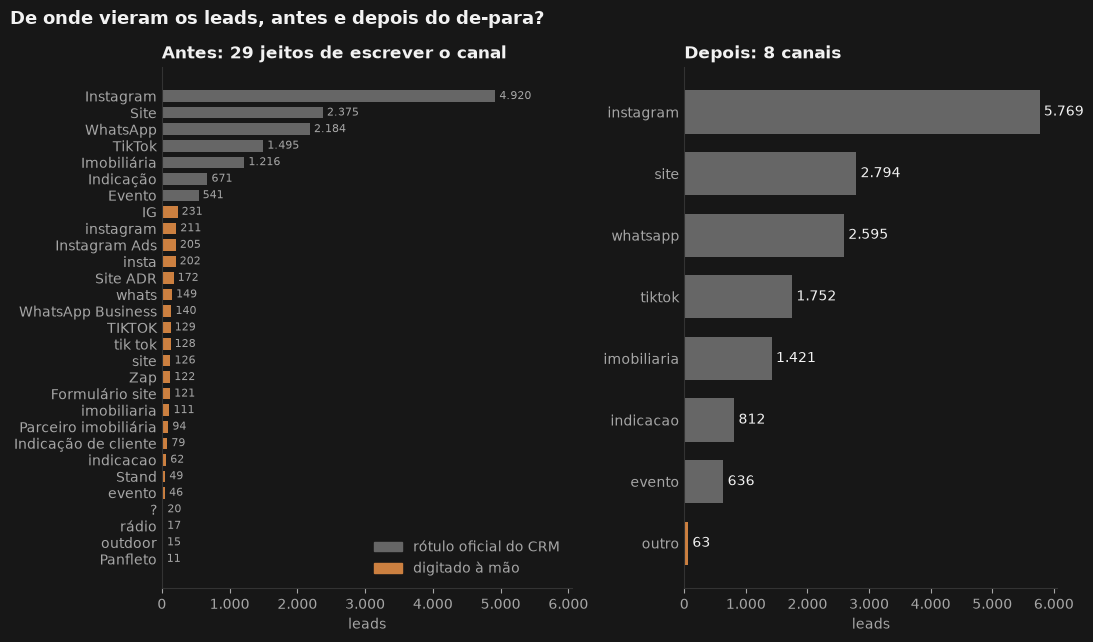

In [17]:
antes_r3 = fotos["r2_textos.tratar"]["lead"]["canal"].fillna("(vazio)").value_counts()
depois_r3 = fotos["r3_canais.tratar"]["lead"]["canal"].value_counts()

fig, (esq, dir) = plt.subplots(1, 2, figsize=(11, 6.5), sharex=True, gridspec_kw={"width_ratios": [1.1, 1]})
cores = [CINZA if texto in r3_canais.ROTULOS else COBRE for texto in antes_r3.index]
b = esq.barh(antes_r3.index[::-1], antes_r3.values[::-1], color=cores[::-1], height=0.7)
esq.bar_label(b, labels=[milhar(v) for v in antes_r3.values[::-1]], padding=3, color=TEXTO_2, fontsize=8)
esq.set_title(f"Antes: {len(antes_r3)} jeitos de escrever o canal")
esq.legend(handles=[Patch(color=CINZA, label="rótulo oficial do CRM"), Patch(color=COBRE, label="digitado à mão")],
           loc="lower right", labelcolor=TEXTO_2)
cores = [COBRE if canal == "outro" else CINZA for canal in depois_r3.index]
b = dir.barh(depois_r3.index[::-1], depois_r3.values[::-1], color=cores[::-1], height=0.7)
dir.bar_label(b, labels=[milhar(v) for v in depois_r3.values[::-1]], padding=3, color=TEXTO)
dir.set_title(f"Depois: {len(depois_r3)} canais")
for ax in (esq, dir):
    ax.set_xlabel("leads")
    ax.xaxis.set_major_formatter(lambda v, _: milhar(int(v)))
    ax.tick_params(axis="y", length=0)
fig.suptitle("De onde vieram os leads, antes e depois do de-para?", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [18]:
registros("r3_canais.tratar")

,regra,origem,o que fez,linhas,ação
0,R3,crm_leads.csv,Canal digitado à mão trocado pelo canal oficial,2377,corrigido
1,R3,crm_leads.csv,"Canal que o dicionário não reconhece, classificado como outro: ?, outdoor, Panfleto, r...",63,outro


### R4 · Datas impossíveis

Algumas datas não têm como estar certas: parcela vencendo depois de 2035 e venda anterior à entrada do
lead do cliente no CRM. Não dá para saber a data certa, então a linha vai para a quarentena.

In [19]:
quarentena_r4 = pd.DataFrame([{"tabela": q["tabela"], "id": q["registro"]["id"], "motivo": q["motivo"]}
                              for q in passos["r4_datas.barrar_impossiveis"].quarentena])
quarentena_r4.groupby("tabela").head(3)

,tabela,id,motivo
0,parcela,6342,vencimento impossível: 2099-12-02
1,parcela,6877,vencimento impossível: 2099-12-10
2,parcela,6928,vencimento impossível: 2099-03-11
4,venda,175,"venda em 2024-05-20, antes da entrada do lead em 2025-02-13"
5,venda,264,"venda em 2025-04-26, antes da entrada do lead em 2025-12-31"


In [20]:
registros("r4_datas.barrar_impossiveis")

,regra,origem,o que fez,linhas,ação
0,R4,erp_parcelas.csv,Vencimento impossível (depois de 2035),4,quarentena
1,R4,comercial_espelho.xlsx,Venda com data anterior à entrada do lead no CRM,2,quarentena


### R5 · Valores fora da faixa

Um zero a mais no valor da venda é fácil de digitar e difícil de ver numa planilha com milhares de
linhas. O R5 calcula o preço por m² de cada venda e uma cerca de 3 × IQR por empreendimento (a
distância entre o 1º e o 3º quartil). O que passa da cerca e volta para dentro dividido por 10 é
corrigido; o resto vai para a quarentena.

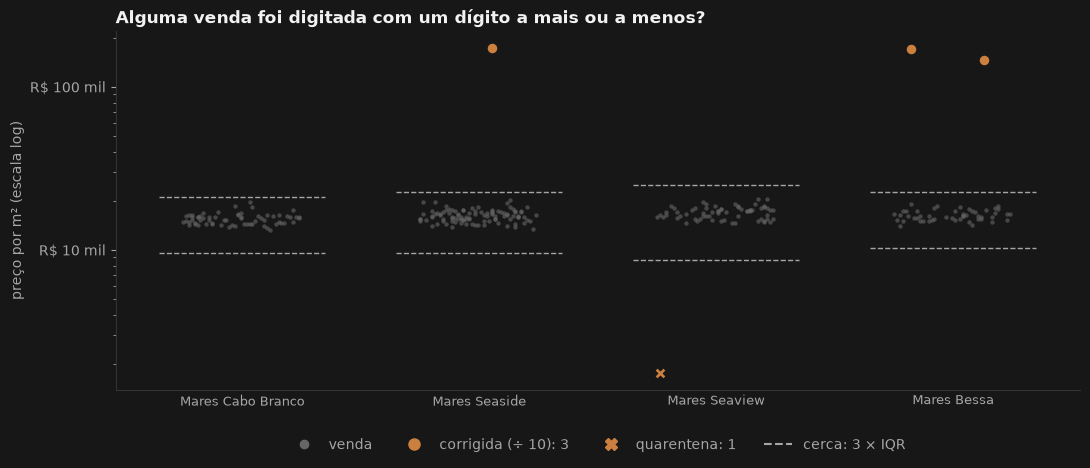

In [21]:
antes_r5 = fotos["r4_datas.barrar_impossiveis"]
venda = antes_r5["venda"].merge(antes_r5["unidade"][["id", "empreendimento_id", "area_privativa_m2"]],
                                left_on="unidade_id", right_on="id", suffixes=("", "_unidade"))
venda["preco_m2"] = venda["valor_venda"] / venda["area_privativa_m2"]
nomes = antes_r5["empreendimento"].set_index("id")["nome"]
corrigidas = passos["r5_valores.corrigir_outliers"].registros[0].ids
barradas = passos["r5_valores.corrigir_outliers"].registros[1].ids

fig, ax = plt.subplots(figsize=(11, 4.8))
for posicao, (emp_id, grupo_emp) in enumerate(venda.groupby("empreendimento_id")):
    q1, q3 = grupo_emp["preco_m2"].quantile([0.25, 0.75])
    cercas = [q1 - r5_valores.CERCA * (q3 - q1), q3 + r5_valores.CERCA * (q3 - q1)]
    deslocamento = (grupo_emp["id"] % 41 / 41 - 0.5) * 0.5  # espalha os pontos sem sorteio
    corrigida, barrada = grupo_emp["id"].isin(corrigidas), grupo_emp["id"].isin(barradas)
    normal = ~corrigida & ~barrada
    ax.scatter(posicao + deslocamento[normal], grupo_emp.loc[normal, "preco_m2"], s=10, color=CINZA, alpha=0.6, linewidths=0)
    ax.scatter(posicao + deslocamento[corrigida], grupo_emp.loc[corrigida, "preco_m2"], s=70, color=COBRE,
               edgecolors=FUNDO, linewidths=1.5, zorder=3)
    ax.scatter(posicao + deslocamento[barrada], grupo_emp.loc[barrada, "preco_m2"], s=70, color=COBRE, marker="X",
               edgecolors=FUNDO, linewidths=1, zorder=3)
    ax.hlines([c for c in cercas if c > 0], posicao - 0.35, posicao + 0.35, color=TEXTO_2, linestyles="dashed", linewidth=1)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(lambda v, _: f"R$ {milhar(int(v / 1000))} mil")
ax.set_xticks(range(venda["empreendimento_id"].nunique()),
              [nomes[e] for e in sorted(venda["empreendimento_id"].unique())], fontsize=9)
ax.tick_params(axis="x", length=0)
ax.set_ylabel("preço por m² (escala log)")
ax.set_title("Alguma venda foi digitada com um dígito a mais ou a menos?")
ax.legend(handles=[plt.Line2D([], [], color=CINZA, marker="o", linestyle="", label="venda"),
                   plt.Line2D([], [], color=COBRE, marker="o", markersize=8, linestyle="", label=f"corrigida (÷ 10): {len(corrigidas)}"),
                   plt.Line2D([], [], color=COBRE, marker="X", markersize=8, linestyle="", label=f"quarentena: {len(barradas)}"),
                   plt.Line2D([], [], color=TEXTO_2, linestyle="dashed", label=f"cerca: {r5_valores.CERCA:g} × IQR")],
          loc="upper center", bbox_to_anchor=(0.5, -0.1), labelcolor=TEXTO_2, ncols=4)
fig.tight_layout()
fig.savefig(RAIZ / "docs" / "img" / "notebook-preco-m2.png", dpi=150, metadata={"Software": None})
plt.show()

In [22]:
saida = antes_e_depois("venda", ["valor_venda"], corrigidas, "r4_datas.barrar_impossiveis", "r5_valores.corrigir_outliers")
saida

valor_venda           
          antes     depois
id                        
148   3218395.2  321839.52
195   3262485.2  326248.52
211   3942527.5  394252.75

In [23]:
registros("r5_valores.corrigir_outliers")

,regra,origem,o que fez,linhas,ação
0,R5,comercial_espelho.xlsx,"Valor da venda com um zero a mais, dividido por 10",3,corrigido
1,R5,comercial_espelho.xlsx,Valor da venda fora da faixa que ÷ 10 não resolve,1,quarentena


### R7 · Pagamentos órfãos

Baixa do ERP apontando para uma parcela que não existe. Sem a parcela, não dá para saber de que venda é o
dinheiro, então o pagamento vai para a quarentena.

In [24]:
pd.DataFrame([{"id": q["registro"]["id"], "motivo": q["motivo"]} for q in passos["r7_orfaos.tratar"].quarentena])

,id,motivo
0,3264,parcela 904122 não existe no ERP
1,3519,parcela 902858 não existe no ERP
2,3780,parcela 907169 não existe no ERP
3,4607,parcela 908240 não existe no ERP
4,4963,parcela 909539 não existe no ERP
5,5589,parcela 902496 não existe no ERP


### A cascata

O que depende de uma linha barrada vai junto, para o banco não ficar com filho sem pai: o lead barrado
leva o cliente, o cliente leva a venda, a venda leva as parcelas e as parcelas levam os pagamentos. A
linha que vai junto herda a regra de quem a levou.

In [25]:
registros("cascata")

,regra,origem,o que fez,linhas,ação
0,R4,comercial_espelho.xlsx,Cliente que depende de linha em quarentena (cascata),2,cascata
1,R4,erp_baixas.csv,Pagamento que depende de linha em quarentena (cascata),12,cascata
2,R4,erp_parcelas.csv,Parcela que depende de linha em quarentena (cascata),42,cascata
3,R5,comercial_espelho.xlsx,Cliente que depende de linha em quarentena (cascata),1,cascata
4,R5,erp_baixas.csv,Pagamento que depende de linha em quarentena (cascata),28,cascata
5,R5,erp_parcelas.csv,Parcela que depende de linha em quarentena (cascata),46,cascata


## 3. Validar

A última barreira antes de gravar o banco: 10 checagens sobre as tabelas tratadas. Se qualquer uma
falha, o `validar()` levanta `ErroDeValidacao` com todas as falhas, e o pipeline para sem gravar nada.

In [26]:
for numero, checagem in enumerate(validar.validar(final.tabelas), start=1):
    print(f"{numero:>2}. {checagem}: ok")

 1. colunas do modelo: ok
 2. chave primária única: ok
 3. chave estrangeira existe: ok
 4. valor dentro do domínio: ok
 5. valor dentro da faixa: ok
 6. uma venda ativa por unidade: ok
 7. distrato só em venda distratada: ok
 8. pagamento até o valor da parcela: ok
 9. um cliente por lead: ok
10. telefone em E.164: ok


Para ver a barreira funcionando, quebro uma chave estrangeira à mão: um pagamento passa a apontar para uma parcela que não existe.

In [27]:
quebrado = dict(final.tabelas)
quebrado["pagamento"] = final.tabelas["pagamento"].copy()
quebrado["pagamento"].loc[0, "parcela_id"] = 999_999

try:
    validar.validar(quebrado)
except validar.ErroDeValidacao as erro:
    print(erro)

A validação falhou; nada foi gravado:
  - chave estrangeira existe: pagamento.parcela_id → parcela: 1 sem par (ex.: 999999)


## 4. A quarentena

Nada é apagado: a linha barrada vai inteira para `auditoria.quarentena`, com a regra e o motivo, e
pode ser consultada por SQL (`sql/consultas/console/05_quarentena_por_motivo.sql`). A maior parte dela vem da cascata.

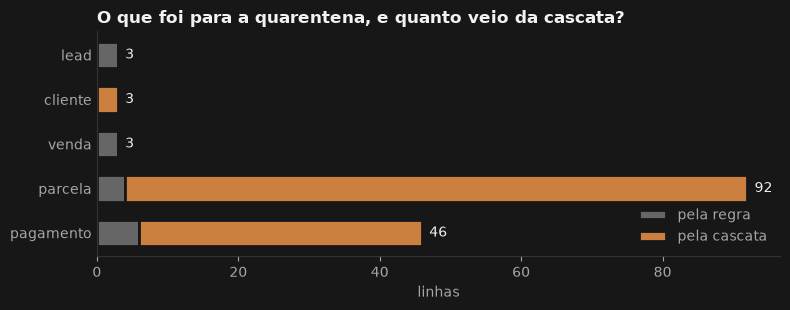

In [28]:
quarentena = pd.DataFrame([{"tabela": q["tabela"], "regra": q["regra"],
                            "como": "pela cascata" if q["motivo"].startswith("depende de") else "pela regra"}
                           for q in final.quarentena])
ORDEM = ["lead", "cliente", "venda", "parcela", "pagamento"]
contagem = quarentena.pivot_table(index="tabela", columns="como", aggfunc="size", fill_value=0).reindex(ORDEM, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.2))
esquerda = pd.Series(0, index=contagem.index)
for como, cor in [("pela regra", CINZA), ("pela cascata", COBRE)]:
    ax.barh(contagem.index[::-1], contagem[como][::-1], left=esquerda[::-1], color=cor, height=0.6,
            edgecolor=FUNDO, linewidth=2, label=como)
    esquerda += contagem[como]
for y, (tabela, total) in enumerate(esquerda[::-1].items()):
    ax.text(total + 1, y, milhar(total), va="center", color=TEXTO)
ax.set_title("O que foi para a quarentena, e quanto veio da cascata?")
ax.set_xlabel("linhas")
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", labelcolor=TEXTO_2)
fig.tight_layout()
plt.show()

In [29]:
quarentena.groupby(["regra", "tabela", "como"]).size().rename("linhas").reset_index()

,regra,tabela,como,linhas
0,R2,lead,pela regra,3
1,R4,cliente,pela cascata,2
2,R4,pagamento,pela cascata,12
3,R4,parcela,pela cascata,42
4,R4,parcela,pela regra,4
5,R4,venda,pela regra,2
6,R5,cliente,pela cascata,1
7,R5,pagamento,pela cascata,28
8,R5,parcela,pela cascata,46
9,R5,venda,pela regra,1


## 5. Fechamento

O relatório de qualidade completo, como ele aparece na tela **Dados** do painel (`auditoria.relatorio_qualidade`):

In [30]:
relatorio = pd.DataFrame([{"regra": r.regra, "origem": r.origem, "descricao": r.descricao,
                           "linhas_afetadas": r.linhas_afetadas, "acao": r.acao} for r in final.registros])
relatorio

,regra,origem,descricao,linhas_afetadas,acao
0,R4,crm_leads.csv,Data de entrada no formato aaaa-mm-dd hh:mm:ss,792,corrigido
1,R5,erp_parcelas.csv,"Valor em texto (R$ 1.234,56) convertido para número",10122,convertido
2,R5,erp_baixas.csv,"Valor em texto (R$ 1.234,56) convertido para número",5594,convertido
3,R1,crm_leads.csv,Leads duplicados (mesmo telefone ou e-mail) mesclados no mais antigo,634,mesclado
4,R6,comercial_espelho.xlsx,Venda sem corretor preenchida com Venda direta,20,corrigido
5,R6,crm_leads.csv,E-mail inválido apagado,285,nulo
6,R2,comercial_espelho.xlsx,Bairro padronizado pelo de-para,3,corrigido
7,R2,crm_leads.csv,Nome de corretor (lead) casado com o cadastro,235,corrigido
8,R2,crm_leads.csv,Nome de corretor (lead) ambíguo ou fora do cadastro,3,quarentena
9,R2,comercial_espelho.xlsx,Nome de corretor (venda) casado com o cadastro,8,corrigido


Como os dados são simulados, o gerador guardou num gabarito (`dados/gabarito.json`) as linhas que ele
mesmo barraria. A quarentena do pipeline bate com ele, tabela por tabela:

In [31]:
gabarito = json.loads((RAIZ / "dados" / "gabarito.json").read_text(encoding="utf-8"))["quarentena_esperada"]
conferencia = pd.DataFrame([{"tabela": t, "esperado": len(ids),
                             "na quarentena": sum(q["tabela"] == t for q in final.quarentena),
                             "mesmos ids": sorted(ids) == sorted(q["registro"]["id"] for q in final.quarentena if q["tabela"] == t)}
                            for t, ids in gabarito.items()])
assert conferencia["mesmos ids"].all()
conferencia

,tabela,esperado,na quarentena,mesmos ids
0,lead,3,3,True
1,cliente,3,3,True
2,venda,3,3,True
3,parcela,92,92,True
4,pagamento,46,46,True


Daqui, o `carregar` grava os CSVs limpos em `dados/limpos/` e monta o banco PostgreSQL que o painel abre
no navegador. Para rodar tudo de uma vez: `python pipeline.py`.